# 12 — exp0b: verification with Monte Carlo responses, with and without standard errors, straddle vs Gotovos

Notebook 10's test-cases and settings (goldstein36_graded, goldstein36_flip, himmelblau36_graded; hs_dim; 10 seeds; 250 samples, no early stopping), but every response is a Monte Carlo estimate as in the CNS campaigns. Three conditions: **A** samples treated as exact, straddle (the campaigns today); **B** standard errors passed to the Gaussian process, straddle; **C** standard errors, Gotovos et al.'s LSE (intervals intersected across iterations, classified points removed, beta^(1/2) = 3). Run where cores are plentiful: `TRC_N_WORKERS=90 jupyter nbconvert --execute ...`; runs are cached in `results/exp0b_runs.pkl`.

In [1]:
import hashlib
import os
import pickle
import sys
import time
from pathlib import Path

os.environ["VECLIB_MAXIMUM_THREADS"] = "1"          # one BLAS thread per worker: the workers are the parallelism
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from joblib import Parallel, delayed
from scipy import special, stats
from mvlse import run_lse, score_level_set
from mvlse.benchmark import test_grid
from mvlse.problems import get_problem

sys.path.insert(0, str(Path.cwd().parent))
import common
import config

P = config.EXPERIMENTS["exp0_verify"]                # same test-cases, seeds, 250 samples, 1 initial per category
TAU = config.TAU                                     # log10 1e-3
N_MC = config.N_ENCOUNTERS                           # 1e5 encounters per sample, as the campaigns
B = 4.6                                              # slope of the probability surface (see the next cell)
CONDITIONS = {
    "A: exact, straddle":  {"se": False, "acquisition": "straddle"},   # as the campaigns run today
    "B: se, straddle":     {"se": True,  "acquisition": "straddle"},
    "C: se, Gotovos LSE":  {"se": True,  "acquisition": "gotovos"},
}
N_WORKERS = int(os.environ.get("TRC_N_WORKERS", "6"))
CACHE = Path("results/exp0b_runs.pkl")
print(P)
print(common.code_state(), f"workers: {N_WORKERS}")

{'problems': ['goldstein36_graded', 'goldstein36_flip', 'himmelblau36_graded'], 'methods': ['category_wise', 'dc', 'gower', 'hs_dim'], 'seeds': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'max_evaluations': 250, 'n_init_per_category': 1}
{'mvlse': {'commit': 'd2c7f3b15111e48ffeb9e62af873476b44a02444', 'dirty': False}, 'blueskycdarr': {'commit': '030c0f459a3c5491cef88485e2672aef60a14179', 'dirty': False}} workers: 90


In [2]:
# Each analytical test-case becomes a probability surface, sampled by Monte Carlo.
#   z = Phi^-1(F(f))   normal score of the test function over its domain (F: its distribution on the test grid)
#   P = logistic(logit(1e-3) + B (z - z_tau))
# Monotone in f, so P <= 1e-3 exactly where f <= its threshold: the level set is notebook 10's. All
# test-cases share one distribution of P over the domain; B = 4.6 puts 15% of the Goldstein domain on
# the zero-loss floor and the rest up to P ~ 1. A sample draws Binomial(1e5, P) losses and reports the
# simulator's own estimate: log10 of the Jeffreys proportion, with its delta-method standard error.
# The draw is a fixed function of (point, seed), like the simulator at seed 7.
# (scipy functions are called through their module: a ufunc imported into the notebook's namespace
# is pickled as __main__.<name>, which the worker processes do not have.)
def surface(name):
    prob = get_problem(name)
    grid = test_grid(prob)
    f_grid = prob.truth(grid)
    s = np.sort(f_grid); n = len(s)
    u_axis = (np.arange(1, n + 1) - 0.5) / n
    F = lambda v: np.interp(v, s, u_axis, left=0.5 / n, right=1 - 0.5 / n)
    z_tau = stats.norm.ppf(F(prob.threshold))
    log_p = lambda w: np.log10(special.expit(special.logit(10.0 ** TAU) + B * (stats.norm.ppf(F(prob.truth(w))) - z_tau)))
    return prob, grid, f_grid <= prob.threshold, log_p


def mc_blackbox(prob, log_p, seed, with_se):
    def blackbox(points):
        w = prob.space.encode(points)
        out = []
        for row, lp in zip(w, log_p(w)):
            key = hashlib.sha256(np.round(row, 9).tobytes() + seed.to_bytes(4, "little")).digest()
            k = np.random.default_rng(int.from_bytes(key[:8], "little")).binomial(N_MC, 10.0 ** lp)
            p_hat = (k + 0.5) / (N_MC + 1.0)
            se = np.sqrt(p_hat * (1 - p_hat) / N_MC) / (p_hat * np.log(10.0))
            out.append((float(np.log10(p_hat)), float(se)) if with_se else float(np.log10(p_hat)))
        return out
    return blackbox


def one_run(name, cond, seed):
    prob, grid, truth_inside, log_p = surface(name)
    t0 = time.perf_counter()
    res = run_lse(prob.space, mc_blackbox(prob, log_p, seed, CONDITIONS[cond]["se"]), threshold=TAU,
                  method=config.LSE["method"], correlation=config.LSE["correlation"], seed=seed,
                  acquisition=CONDITIONS[cond]["acquisition"], max_evaluations=P["max_evaluations"],
                  n_init_per_category=P["n_init_per_category"], flip_tolerance=config.LSE["flip_tolerance"],
                  stop_when_confident=False, monitor=grid, keep_snapshots=True, verbose=False)
    truth_lp = log_p(grid)
    f1 = [score_level_set(mu, truth_lp, TAU).f1 for mu, _ in res.snapshots]
    mu, sd = res.snapshots[-1]
    safe, unsafe = mu + 1.96 * sd <= TAU, mu - 1.96 * sd > TAU
    wrong = (mu <= TAU) != truth_inside
    rec = {
        "n": [r.n_evaluations for r in res.rounds], "f1": f1, "seconds": time.perf_counter() - t0,
        "safe": float(safe.mean()), "unsafe": float(unsafe.mean()), "ambiguous": float((~safe & ~unsafe).mean()),
        "false_safe": float((safe & ~truth_inside).mean()),          # confidently safe, truly unsafe
        "false_unsafe": float((unsafe & truth_inside).mean()),
        "errors_flagged": float(((~safe & ~unsafe) & wrong).sum() / max(wrong.sum(), 1)),
        "w": res.w, "y": res.y, "se": res.se, "level_correlations": res.level_correlations(),
    }
    if res.labels is not None:                                       # Gotovos' own classification, on its candidates
        cand_inside = log_p(res.candidates) <= TAU
        lab = res.labels
        rec |= {"g_unclassified": float(np.mean(lab == 0)),
                "g_false_safe": float(np.mean((lab == 1) & ~cand_inside)),
                "g_false_unsafe": float(np.mean((lab == 2) & cand_inside)),
                "g_wrong_among_classified": float(np.sum(((lab == 1) & ~cand_inside) | ((lab == 2) & cand_inside))
                                                  / max(np.sum(lab > 0), 1))}
    return (name, cond, seed), rec


def run_all(jobs, cache):
    done = pickle.loads(cache.read_bytes()) if cache.exists() else {}
    todo = sorted((j for j in jobs if j not in done), key=lambda j: "himmelblau" not in j[0])
    print(f"{len(jobs) - len(todo)} of {len(jobs)} runs cached, {len(todo)} to run", flush=True)
    t0 = time.perf_counter()
    for key, rec in Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(delayed(one_run)(*j) for j in todo):
        done[key] = rec
        cache.write_bytes(pickle.dumps(done))
        print(f"[{(time.perf_counter() - t0) / 60:6.1f} min] {key[0]:20s} {key[1]:20s} seed {key[2]:2d}: "
              f"F1={rec['f1'][-1]:.4f} false-safe={rec['false_safe']:.4f} [{rec['seconds'] / 60:.1f} min]", flush=True)
    return done


runs = run_all([(n, c, s) for n in P["problems"] for c in CONDITIONS for s in P["seeds"]], CACHE)

0 of 90 runs cached, 90 to run


[   0.1 min] himmelblau36_graded  C: se, Gotovos LSE   seed  3: F1=0.0000 false-safe=0.0000 [0.1 min]


[   0.6 min] himmelblau36_graded  C: se, Gotovos LSE   seed  4: F1=0.0402 false-safe=0.0000 [0.6 min]


[   0.7 min] himmelblau36_graded  C: se, Gotovos LSE   seed  2: F1=0.0225 false-safe=0.0001 [0.7 min]


[   0.8 min] himmelblau36_graded  C: se, Gotovos LSE   seed  1: F1=0.2058 false-safe=0.0000 [0.7 min]


[   0.9 min] himmelblau36_graded  C: se, Gotovos LSE   seed  7: F1=0.0378 false-safe=0.0018 [0.9 min]


... (81 outputs left out)

[ 113.1 min] goldstein36_graded   B: se, straddle      seed  3: F1=0.9965 false-safe=0.0000 [113.0 min]


[ 114.3 min] goldstein36_flip     B: se, straddle      seed  1: F1=0.9961 false-safe=0.0003 [114.3 min]


[ 115.3 min] goldstein36_graded   B: se, straddle      seed  2: F1=0.9965 false-safe=0.0000 [115.3 min]


[ 117.8 min] goldstein36_graded   B: se, straddle      seed  1: F1=0.9970 false-safe=0.0001 [117.8 min]


In [3]:
# Per test-case and condition (mean +- sd over seeds). F1 of the prediction against the truth; then the
# safety reading of the final surrogate model on the test grid, with the same 95% interval for every
# condition: confidently safe but truly unsafe (the dangerous error), and how many of the prediction's
# misclassified points the interval flagged as ambiguous.
def ms(v, f="{:.4f}"):
    v = np.asarray(v, float)
    return f"{f.format(v.mean())} +- {f.format(v.std())}"

rows = []
for name in P["problems"]:
    for cond in CONDITIONS:
        rs = [runs[name, cond, s] for s in P["seeds"]]
        hit = [next((n for n, f in zip(r["n"], r["f1"]) if f >= 0.99), np.nan) for r in rs]
        rows.append({"problem": name, "condition": cond,
                     "F1 at 100": ms([np.interp(100, r["n"], r["f1"]) for r in rs]),
                     "F1 at 250": ms([r["f1"][-1] for r in rs]),
                     "samples to F1 >= 0.99": "never" if np.all(np.isnan(hit)) else ms([h for h in hit if h == h], "{:.0f}")
                                              + ("" if not np.any(np.isnan(hit)) else f" ({np.sum(~np.isnan(hit))}/{len(hit)})"),
                     "false safe [%]": ms([100 * r["false_safe"] for r in rs], "{:.3f}"),
                     "ambiguous [%]": ms([100 * r["ambiguous"] for r in rs], "{:.1f}"),
                     "errors flagged ambiguous [%]": ms([100 * r["errors_flagged"] for r in rs], "{:.0f}"),
                     "minutes per run": f"{np.mean([r['seconds'] for r in rs]) / 60:.0f}"})
table = pd.DataFrame(rows).set_index(["problem", "condition"])
table.to_csv("results/exp0b_summary.csv")
table

F1 at 100         F1 at 250  \
problem             condition                                                
goldstein36_graded  A: exact, straddle  0.9878 +- 0.0027  0.9926 +- 0.0009   
                    B: se, straddle     0.9918 +- 0.0017  0.9963 +- 0.0006   
                    C: se, Gotovos LSE  0.9909 +- 0.0013  0.9952 +- 0.0013   
goldstein36_flip    A: exact, straddle  0.9884 +- 0.0030  0.9923 +- 0.0006   
                    B: se, straddle     0.9924 +- 0.0015  0.9957 +- 0.0005   
                    C: se, Gotovos LSE  0.9911 +- 0.0018  0.9933 +- 0.0014   
himmelblau36_graded A: exact, straddle  0.4635 +- 0.0862  0.6833 +- 0.1308   
                    B: se, straddle     0.4777 +- 0.0906  0.7311 +- 0.0358   
                    C: se, Gotovos LSE  0.1492 +- 0.1445  0.1492 +- 0.1445   

                                       samples to F1 >= 0.99  false safe [%]  \
problem             condition                                                  
goldstein36_graded  A: exact, straddle             120 +- 28  0.082 +- 0.030   
                    B: se, straddle                 82 +- 13  0.002 +- 0.005   
                    C: se, Gotovos LSE              88 +- 12  0.022 +- 0.031   
goldstein36_flip    A: exact, straddle              98 +- 14  0.086 +- 0.018   
                    B: se, straddle                 80 +- 11  0.012 +- 0.012   
                    C: se, Gotovos LSE              86 +- 21  0.046 +- 0.036   
himmelblau36_graded A: exact, straddle                 never  0.106 +- 0.094   
                    B: se, straddle                    never  0.036 +- 0.029   
                    C: se, Gotovos LSE                 never  0.084 +- 0.093   

                                       ambiguous [%]  \
problem             condition                          
goldstein36_graded  A: exact, straddle    2.2 +- 0.1   
                    B: se, straddle       1.8 +- 0.1   
                    C: se, Gotovos LSE    2.3 +- 0.3   
goldstein36_flip    A: exact, straddle    2.2 +- 0.3   
                    B: se, straddle       1.4 +- 0.2   
                    C: se, Gotovos LSE    1.9 +- 0.3   
himmelblau36_graded A: exact, straddle   15.9 +- 4.4   
                    B: se, straddle      12.8 +- 1.8   
                    C: se, Gotovos LSE    7.7 +- 5.4   

                                       errors flagged ambiguous [%]  \
problem             condition                                         
goldstein36_graded  A: exact, straddle                      78 +- 3   
                    B: se, straddle                         98 +- 2   
                    C: se, Gotovos LSE                      94 +- 5   
goldstein36_flip    A: exact, straddle                      77 +- 4   
                    B: se, straddle                         88 +- 6   
                    C: se, Gotovos LSE                     79 +- 10   
himmelblau36_graded A: exact, straddle                     87 +- 22   
                    B: se, straddle                         92 +- 7   
                    C: se, Gotovos LSE                     34 +- 24   

                                       minutes per run  
problem             condition                           
goldstein36_graded  A: exact, straddle              74  
                    B: se, straddle                104  
                    C: se, Gotovos LSE              65  
goldstein36_flip    A: exact, straddle              64  
                    B: se, straddle                 99  
                    C: se, Gotovos LSE              33  
himmelblau36_graded A: exact, straddle              66  
                    B: se, straddle                 77  
                    C: se, Gotovos LSE               1

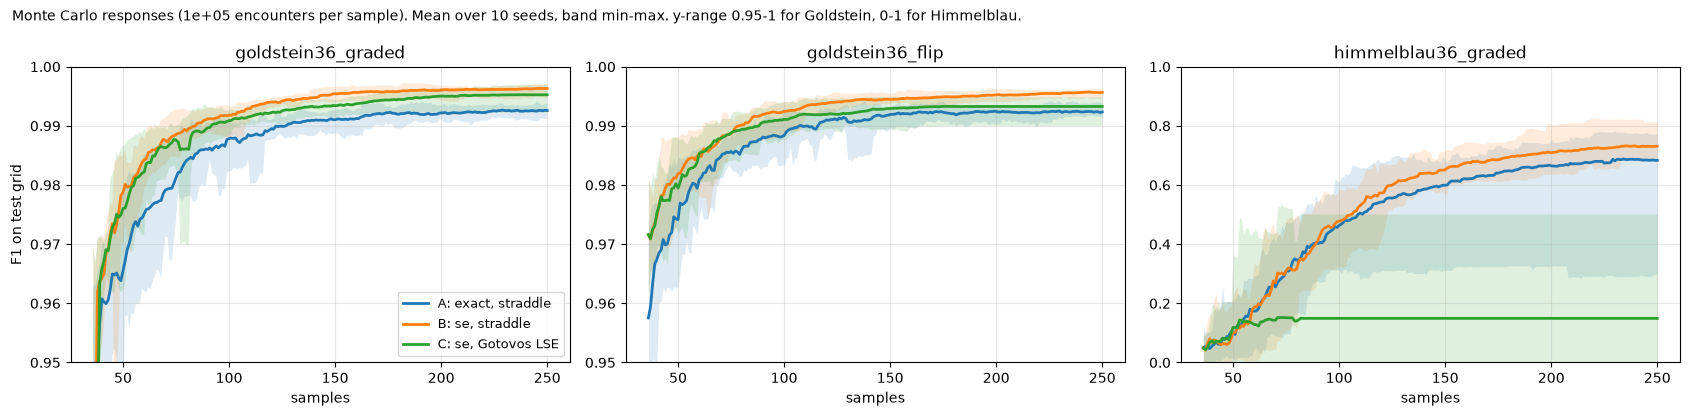

In [4]:
# F1 against samples, linear axis; conditions differ by colour only.
def curve(r, n_axis):
    return np.interp(n_axis, r["n"], r["f1"], right=r["f1"][-1])

n_axis = np.arange(36 * P["n_init_per_category"], P["max_evaluations"] + 1)
colors = {c: f"C{i}" for i, c in enumerate(CONDITIONS)}
ylim = {"goldstein": (0.95, 1.0), "himmelblau": (0.0, 1.0)}
fig, axes = plt.subplots(1, len(P["problems"]), figsize=(17, 4.2), squeeze=False)
for ax, name in zip(axes.flat, P["problems"]):
    for cond in CONDITIONS:
        c = np.array([curve(runs[name, cond, s], n_axis) for s in P["seeds"]])
        ax.plot(n_axis, c.mean(axis=0), color=colors[cond], lw=2, label=cond)
        ax.fill_between(n_axis, c.min(axis=0), c.max(axis=0), color=colors[cond], alpha=0.15, lw=0)
    ax.set_ylim(*ylim[name.split("36")[0]]); ax.set_title(name); ax.set_xlabel("samples"); ax.grid(alpha=0.3)
axes.flat[0].set_ylabel("F1 on test grid"); axes.flat[0].legend(fontsize=9, loc="lower right")
fig.suptitle(f"Monte Carlo responses ({N_MC:.0e} encounters per sample). Mean over {len(P['seeds'])} seeds, band min-max. "
             "y-range 0.95-1 for Goldstein, 0-1 for Himmelblau.", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.savefig("results/exp0b_f1_vs_samples.pdf"); plt.show()

In [5]:
# Gotovos LSE on its own terms: its monotone classification of the candidate points.
rows = []
for name in P["problems"]:
    rs = [runs[name, "C: se, Gotovos LSE", s] for s in P["seeds"]]
    rows.append({"problem": name,
                 "unclassified at 250 [%]": ms([100 * r["g_unclassified"] for r in rs], "{:.1f}"),
                 "false safe [%]": ms([100 * r["g_false_safe"] for r in rs], "{:.3f}"),
                 "false unsafe [%]": ms([100 * r["g_false_unsafe"] for r in rs], "{:.3f}"),
                 "wrong among classified [%]": ms([100 * r["g_wrong_among_classified"] for r in rs], "{:.3f}")})
pd.DataFrame(rows).set_index("problem")

,unclassified at 250 [%],false safe [%],false unsafe [%],wrong among classified [%]
problem,,,,
goldstein36_graded,1.2 +- 0.3,2.118 +- 4.591,0.608 +- 1.145,2.746 +- 5.763
goldstein36_flip,0.9 +- 0.2,0.308 +- 0.160,0.851 +- 0.322,1.169 +- 0.408
himmelblau36_graded,0.0 +- 0.0,1.125 +- 1.549,5.105 +- 0.506,6.231 +- 1.460


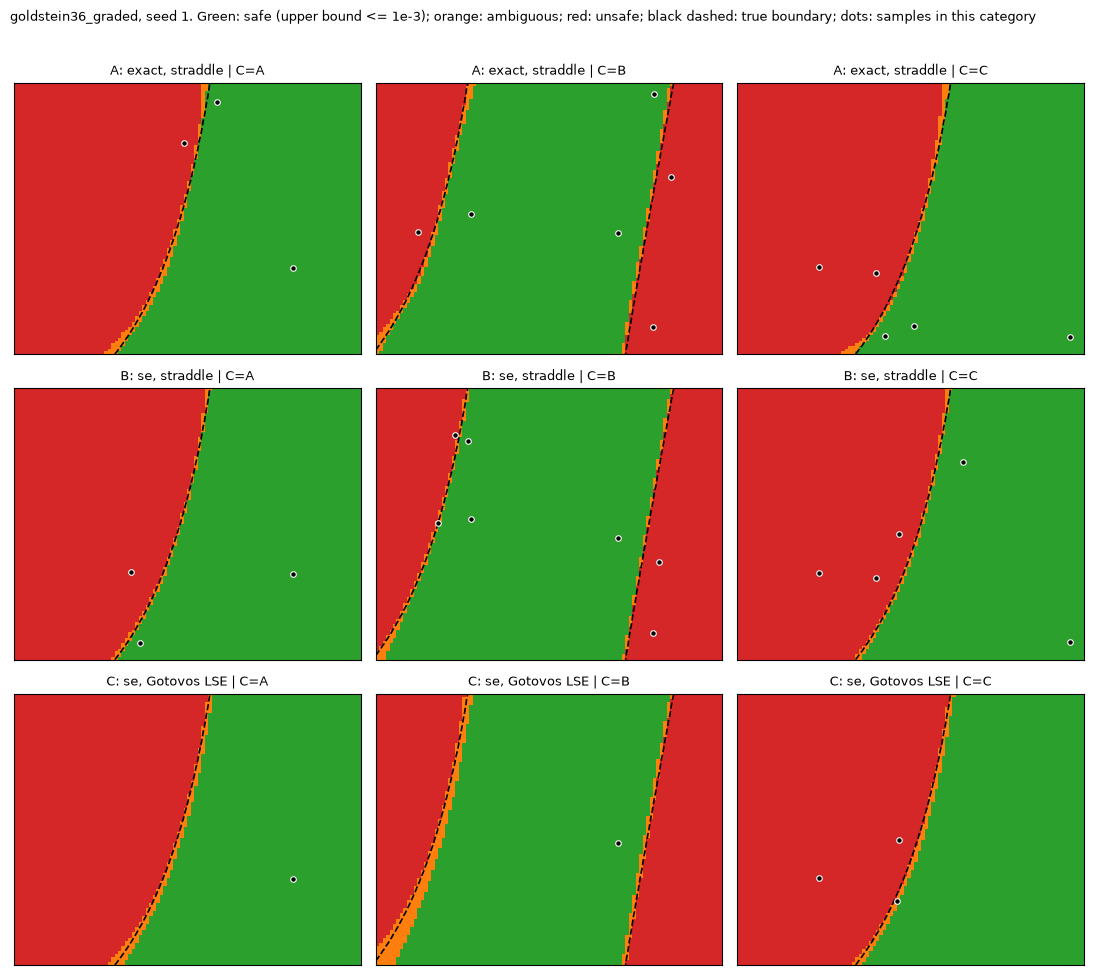

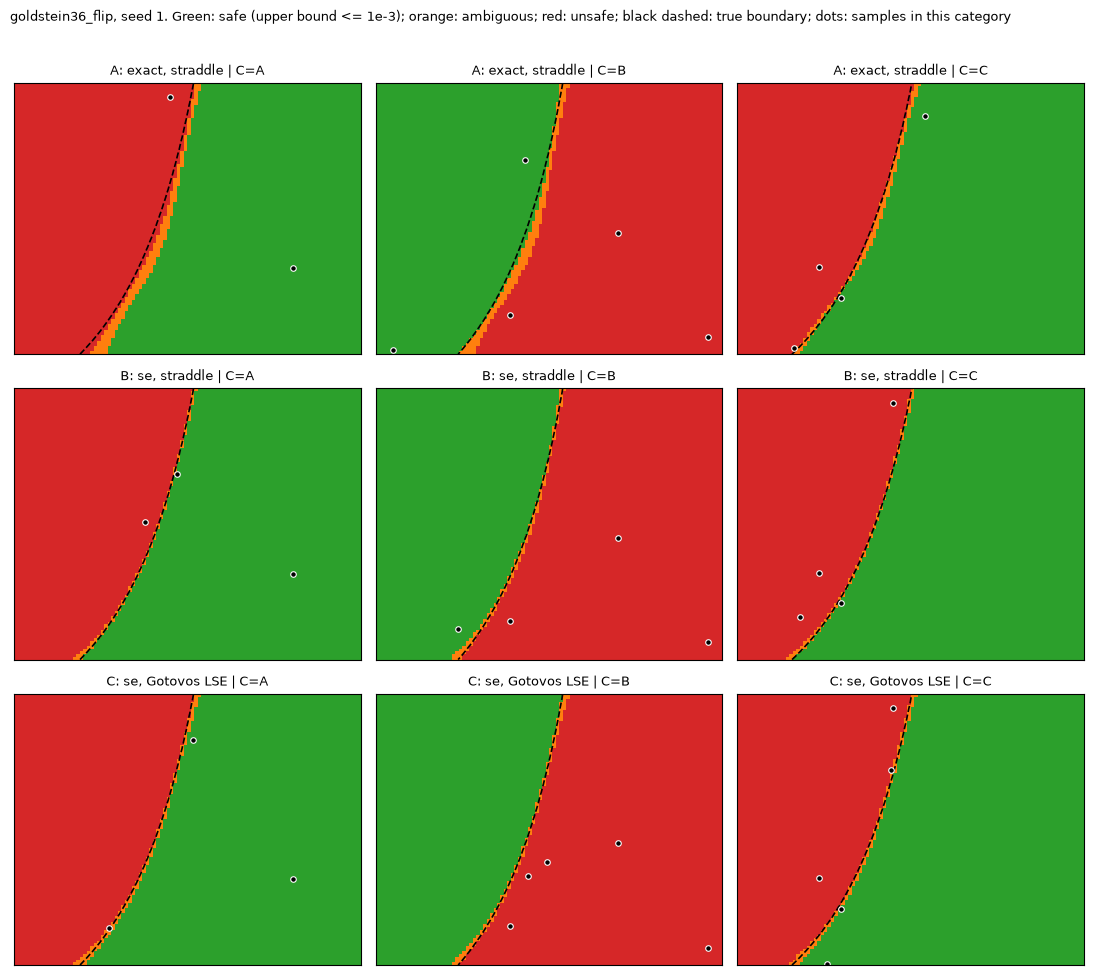

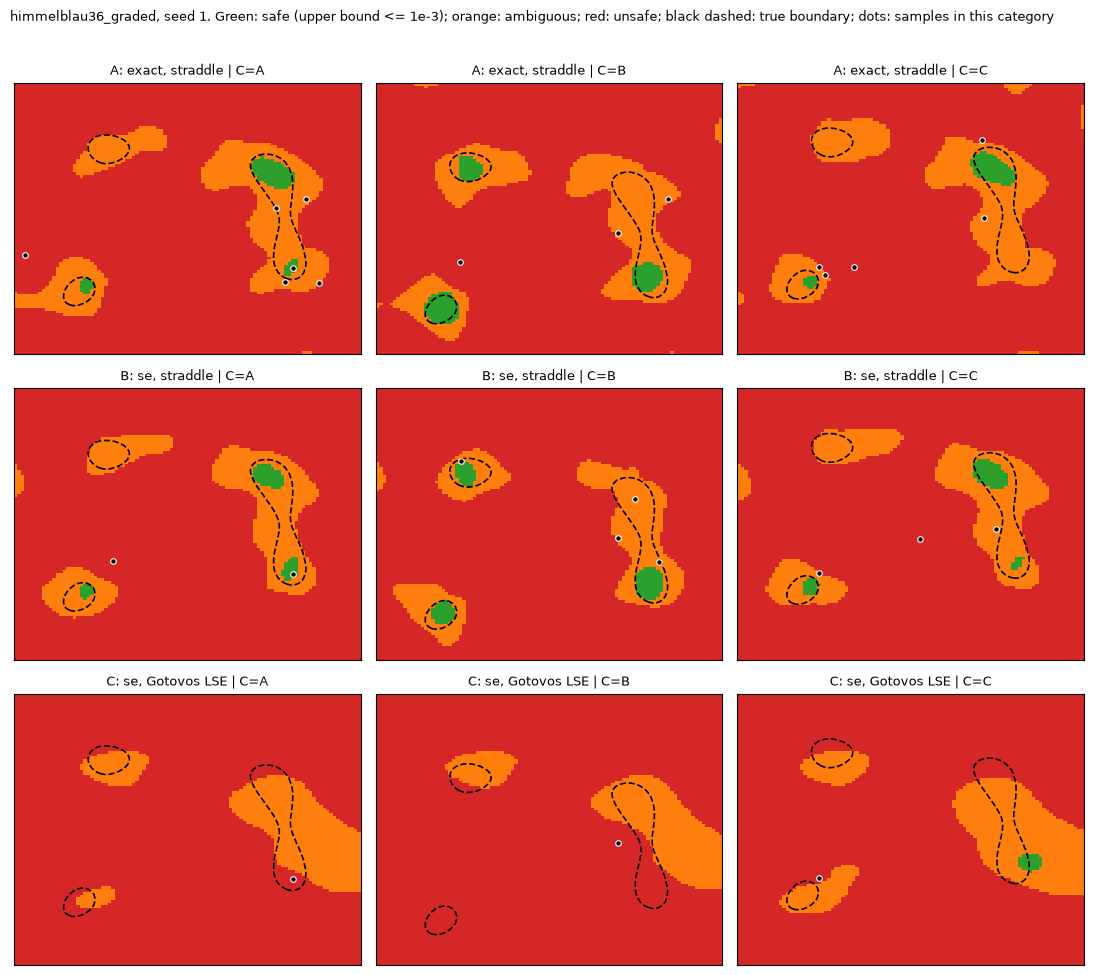

In [6]:
# Safe / ambiguous / unsafe on a slice, seed 1, per condition (rows) and level of C (columns).
# Black dashed: true boundary. Slice as notebook 10: first two continuous variables, third at mid-range,
# the other discrete variables at level 1.
from mvlse import fit_surrogate

THREE = ListedColormap(["tab:red", "tab:orange", "tab:green"])
N = 100
for name in P["problems"]:
    prob, grid, _, log_p = surface(name)
    sp = prob.space
    (a_lo, a_hi), (b_lo, b_hi) = sp.continuous_bounds[0], sp.continuous_bounds[1]
    g1, g2 = np.meshgrid(np.linspace(0, 1, N), np.linspace(0, 1, N))
    pa, pb = a_lo + g1 * (a_hi - a_lo), b_lo + g2 * (b_hi - b_lo)
    fig, axes = plt.subplots(len(CONDITIONS), 3, figsize=(11, 3.3 * len(CONDITIONS)), sharex=True, sharey=True)
    for i, cond in enumerate(CONDITIONS):
        r = runs[name, cond, 1]
        model = fit_surrogate(config.LSE["method"], sp, r["w"], r["y"], r["se"] if CONDITIONS[cond]["se"] else None,
                              rng=np.random.default_rng(0))
        for k, level in enumerate(sp.variable(sp.discrete_names[-1]).levels):
            w = np.column_stack([g1.ravel(), g2.ravel(), np.full(N * N, 0.5), np.full(N * N, 1),
                                 np.full(N * N, 1), np.full(N * N, k)])
            mu, sd = model.predict(w)
            cls = np.where(mu + 1.96 * sd <= TAU, 2, np.where(mu - 1.96 * sd > TAU, 0, 1)).reshape(N, N)
            ax = axes[i, k]
            ax.imshow(cls, origin="lower", extent=(a_lo, a_hi, b_lo, b_hi), cmap=THREE, vmin=0, vmax=2, aspect="auto",
                      interpolation="nearest")
            ax.contour(pa, pb, log_p(w).reshape(N, N), levels=[TAU], colors="black", linewidths=1.2, linestyles="--")
            cat = (r["w"][:, 3] == 1) & (r["w"][:, 4] == 1) & (r["w"][:, 5] == k)
            ax.plot(a_lo + r["w"][cat, 0] * (a_hi - a_lo), b_lo + r["w"][cat, 1] * (b_hi - b_lo), "o", ms=4,
                    mfc="black", mec="white", mew=0.8)
            ax.set_title(f"{cond} | C={level}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{name}, seed 1. Green: safe (upper bound <= 1e-3); orange: ambiguous; red: unsafe; "
                 "black dashed: true boundary; dots: samples in this category", x=0.01, ha="left", fontsize=9)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## The boundary with and without standard errors

Same Monte Carlo samples problem, seed 1, same slice as above. Pale fill: the true level set (green inside). Black dashed: true boundary. Blue: boundary of the prediction when samples are treated as exact (A). Orange: with standard errors (B).

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from mvlse import fit_surrogate

PALE = ListedColormap(["#f6d5d5", "#d7efd7"])                      # outside, inside
LINES = {"A: exact, straddle": "C0", "B: se, straddle": "C1"}
N = 120
fig, axes = plt.subplots(len(P["problems"]), 3, figsize=(13, 4.0 * len(P["problems"])), squeeze=False)
for row, name in enumerate(P["problems"]):
    prob, grid, _, log_p = surface(name)
    sp = prob.space
    (a_lo, a_hi), (b_lo, b_hi) = sp.continuous_bounds[0], sp.continuous_bounds[1]
    g1, g2 = np.meshgrid(np.linspace(0, 1, N), np.linspace(0, 1, N))
    pa, pb = a_lo + g1 * (a_hi - a_lo), b_lo + g2 * (b_hi - b_lo)
    models = {}
    for cond in LINES:
        r = runs[name, cond, 1]
        models[cond] = fit_surrogate(config.LSE["method"], sp, r["w"], r["y"], r["se"] if CONDITIONS[cond]["se"] else None,
                                     rng=np.random.default_rng(0))
    for k, level in enumerate(sp.variable(sp.discrete_names[-1]).levels):
        ax = axes[row, k]
        w = np.column_stack([g1.ravel(), g2.ravel(), np.full(N * N, 0.5), np.full(N * N, 1), np.full(N * N, 1), np.full(N * N, k)])
        truth = log_p(w).reshape(N, N)
        ax.imshow((truth <= TAU).astype(float), origin="lower", extent=(a_lo, a_hi, b_lo, b_hi), cmap=PALE, vmin=0, vmax=1,
                  aspect="auto", interpolation="nearest")
        ax.contour(pa, pb, truth, levels=[TAU], colors="black", linewidths=1.6, linestyles="--")
        txt = []
        for cond, color in LINES.items():
            mu = models[cond].predict(w)[0].reshape(N, N)
            ax.contour(pa, pb, mu, levels=[TAU], colors=color, linewidths=2.0)
            txt.append(f"{cond[0]} {np.mean((mu <= TAU) != (truth <= TAU)):.1%} wrong")
        ax.set_title(f"{name} | C={level}\n" + ", ".join(txt), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
fig.legend([Line2D([], [], color="black", ls="--", lw=1.6)] + [Line2D([], [], color=c, lw=2) for c in LINES.values()],
           ["true boundary"] + [f"{c} (predicted)" for c in LINES], loc="upper center", ncol=3, frameon=False, fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig("results/exp0b_boundaries_se_vs_exact.png", dpi=130)
plt.show()

## Insight

*Run on satsvr01 (90 workers), commits `d2c7f3b` / `030c0f4`; 10 seeds per cell.*

**1. Telling the Gaussian process how precise each sample is makes it both more accurate and more
honest.** With the Monte Carlo variance on the diagonal of the covariance matrix (B), the surrogate
model reaches F1 = 0.99 on the Goldstein test-cases after 80–82 samples, against 98–120 when every
sample is treated as exact (A), and ends higher (0.996 against 0.992). The dangerous error, points
declared safe with confidence that are truly unsafe, falls from 0.08% of the domain to 0.002–0.012%
(7–40×), and on Himmelblau from 0.11% to 0.04%. The ambiguous region also covers more of the
remaining errors (88–98% against 77–87%). Treated as exact, the model must pass through every noisy
estimate, so its modelling uncertainty is zero exactly where the data are least reliable: it is
over-confident, and the over-confidence lands on the boundary.

**2. Monte Carlo noise costs samples.** Without noise (notebook 10) the same models reached
F1 = 0.99 after 42–56 samples; with 10⁵ encounters per sample they need 80–120. On Himmelblau, F1
after 250 samples is 0.73 (B) against 0.88 without noise.

**3. Gotovos et al.'s LSE stops itself, and on disjoint regions it stops too early.** Its
classification is irreversible: once a candidate's intersected interval clears the threshold it is
classified for good and never sampled. It therefore ends when the candidates run out, after 132–240
samples on Goldstein and 36–83 on Himmelblau, where it declares the small safe regions unsafe before
ever sampling them (F1 = 0.15; false unsafe 5.1% of its candidates). Its own labels are wrong for
1–6% of the candidates it classified. Its guarantee assumes a fixed, correctly specified Gaussian
process; here the hyperparameters are re-estimated every round, and an early model's interval is
intersected into every later one. On the smooth Goldstein boundary it is competitive with B up to
about 100 samples.

**4. For the CNS campaigns:** pass the standard errors (B), keep the straddle, and keep the fixed
number of samples. The cost is in fitting time only (≈100 against ≈70 min per test-case run, one
more hyperparameter), which is small next to the simulator. The exp1 campaign ran as A; its samples
can be refitted with standard errors recomputed from their loss counts without new simulations,
although the samples themselves were chosen by an over-confident model.
